<a href="https://colab.research.google.com/github/HannaVar1/belhard_project/blob/main/03_capture_regression_final_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Для итоговой оценки зафиксированы SVR и PyTorch MLP из регрессионного эксперимента B, использующие боевые характеристики, рост, вес, типы, цвет и форму тела. Предпочтительным кандидатом по validation MAE является MLP B.

Основные результаты рассчитываются по исходным прогнозам без округления и clipping. Дополнительно оценивается заранее заданное ограничение прогнозов диапазоном [0, 255], одинаковое для всех моделей. Преобразования данных и target загружаются из B и не переобучаются. После просмотра test настройки моделей не изменяются.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

import torch
from torch import nn

from IPython.display import display

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

DATA_PATH = Path(
    "/content/drive/MyDrive/datasets/pokemon_complete.csv"
)

B_DIR = Path(
    "/content/drive/MyDrive/regression_results_B"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/regression_final_test"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS_PATH = B_DIR / "regression_models.joblib"
CHECKPOINT_PATH = B_DIR / "mlp_checkpoint.pt"
SPLIT_PATH = B_DIR / "split.csv"

START_MARKER = OUTPUT_DIR / "evaluation_started.json"
COMPLETION_MARKER = OUTPUT_DIR / "evaluation_completed.json"
FAILURE_MARKER = OUTPUT_DIR / "evaluation_failed.json"

DEVICE = torch.device("cpu")

RANGE_BINS = [-1, 30, 100, 200, 255]
RANGE_LABELS = ["0–30", "31–100", "101–200", "201–255"]

SELECTED_MODEL = "PyTorch MLP B"
PRIMARY_VARIANT = "raw"

sns.set_theme(style="whitegrid")


def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


def regression_metrics(y_true, prediction):
    prediction = np.asarray(prediction).ravel()

    return {
        "MAE": mean_absolute_error(y_true, prediction),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, prediction)
        ),
        "R2": r2_score(y_true, prediction),
        "outside_0_255": int(
            ((prediction < 0) | (prediction > 255)).sum()
        ),
    }


def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


for path in [
    DATA_PATH, MODELS_PATH, CHECKPOINT_PATH, SPLIT_PATH
]:
    if not path.is_file():
        raise FileNotFoundError(f"Не найден файл: {path}")

# Загрузка — без fit и без повторного обучения.
bundle = joblib.load(MODELS_PATH)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True,
)

required_bundle_keys = [
    "baseline_median",
    "baseline_mean",
    "svr",
    "mlp_feature_preprocessor",
    "mlp_target_scaler",
    "numeric_features",
    "categorical_features",
    "features",
    "target",
]

missing = set(required_bundle_keys) - set(bundle)

if missing:
    raise ValueError(
        f"В артефактах B отсутствуют поля: {sorted(missing)}"
    )

required_checkpoint_keys = [
    "state_dict", "input_dim", "features",
    "target", "best_epoch", "dropout",
]

missing = set(required_checkpoint_keys) - set(checkpoint)

if missing:
    raise ValueError(
        f"В checkpoint отсутствуют поля: {sorted(missing)}"
    )

baseline_median_B = bundle["baseline_median"]
baseline_mean_B = bundle["baseline_mean"]
svr_B = bundle["svr"]

feature_preprocessor_B = bundle["mlp_feature_preprocessor"]
target_scaler_B = bundle["mlp_target_scaler"]

NUMERIC_FEATURES = bundle["numeric_features"]
CATEGORICAL_FEATURES = bundle["categorical_features"]
FEATURES = bundle["features"]

TARGET = bundle["target"]
GROUP = "evolution_chain_id"

expected_numeric = [
    "hp", "attack", "defense",
    "sp_attack", "sp_defense", "speed",
    "height_m", "weight_kg",
]

expected_categorical = [
    "type_1", "type_2", "color", "shape",
]

if NUMERIC_FEATURES != expected_numeric:
    raise ValueError("Неожиданные числовые признаки")

if CATEGORICAL_FEATURES != expected_categorical:
    raise ValueError("Загружены не ожидаемые признаки B")

if FEATURES != NUMERIC_FEATURES + CATEGORICAL_FEATURES:
    raise ValueError("Некорректный порядок признаков")

if TARGET != "capture_rate" or checkpoint["target"] != TARGET:
    raise ValueError("Неожиданная целевая переменная")

if checkpoint["features"] != FEATURES:
    raise ValueError("Признаки checkpoint и preprocessing различаются")

if not np.isclose(checkpoint["dropout"], 0.1):
    raise ValueError("Неожиданная настройка Dropout")

if bundle.get("prediction_postprocessing", "none") != "none":
    raise ValueError(
        "Артефакт содержит другую постобработку. "
        "Нужны исходные модели B."
    )

# Архитектура точно повторяет регрессионную MLP B.
mlp_B = nn.Sequential(
    nn.Linear(checkpoint["input_dim"], 64),
    nn.ReLU(),
    nn.Dropout(0.1),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
).to(DEVICE)

mlp_B.load_state_dict(checkpoint["state_dict"])
mlp_B.eval()

print("Загружены регрессионные модели B")
print("Признаки:", FEATURES)
print("Лучшая сохранённая эпоха MLP:", checkpoint["best_epoch"])
print("Основной вариант прогнозов:", PRIMARY_VARIANT)
print("Кандидат, выбранный по validation:", SELECTED_MODEL)

Загружены регрессионные модели B
Признаки: ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 'height_m', 'weight_kg', 'type_1', 'type_2', 'color', 'shape']
Лучшая сохранённая эпоха MLP: 17
Основной вариант прогнозов: raw
Кандидат, выбранный по validation: PyTorch MLP B


In [ ]:
raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

required_columns = [
    "pokedex_number", "name", GROUP, TARGET, *FEATURES
]

missing = set(required_columns) - set(raw.columns)

if missing:
    raise ValueError(
        f"В CSV отсутствуют поля: {sorted(missing)}"
    )

raw["pokedex_number"] = pd.to_numeric(
    raw["pokedex_number"], errors="raise"
)

df = raw.loc[
    raw["pokedex_number"].between(1, 1025)
].copy().reset_index(drop=True)

if df.empty or not df["pokedex_number"].is_unique:
    raise ValueError("Пустая выборка или повторяющиеся ID")

numeric_columns = [GROUP, TARGET, *NUMERIC_FEATURES]

df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric, errors="raise"
)

if df[numeric_columns].isna().any().any():
    raise ValueError("Пропуски в числовых полях")

if not np.isfinite(
    df[numeric_columns].to_numpy(dtype=float)
).all():
    raise ValueError("Бесконечные числовые значения")

if (df[NUMERIC_FEATURES] < 0).any().any():
    raise ValueError("Отрицательные значения признаков")

if not df[TARGET].between(0, 255).all():
    raise ValueError("Capture rate вне диапазона 0–255")

# Та же обработка категорий, что в B.
df["type_2"] = (
    df["type_2"]
    .fillna("__none__")
    .astype(str)
    .str.strip()
    .replace("", "__none__")
)

for column in ["type_1", "color", "shape"]:
    if df[column].isna().any():
        raise ValueError(f"Пропуски в {column}")

    df[column] = df[column].astype(str).str.strip()

    if df[column].eq("").any():
        raise ValueError(f"Пустые категории в {column}")

saved_split = pd.read_csv(
    SPLIT_PATH, encoding="utf-8-sig"
)

required_split = [
    "pokedex_number", GROUP, TARGET, "split"
]

missing = set(required_split) - set(saved_split.columns)

if missing:
    raise ValueError(
        f"В split.csv отсутствуют поля: {sorted(missing)}"
    )

if saved_split[required_split].isna().any().any():
    raise ValueError("Пропуски в split.csv")

for column in ["pokedex_number", GROUP, TARGET]:
    saved_split[column] = pd.to_numeric(
        saved_split[column], errors="raise"
    )

saved_split["split"] = (
    saved_split["split"].astype(str).str.strip()
)

if not saved_split["pokedex_number"].is_unique:
    raise ValueError("Повторяющиеся ID в split.csv")

if set(saved_split["split"]) != {
    "train", "validation", "test"
}:
    raise ValueError("Некорректные названия частей выборки")

if set(saved_split["pokedex_number"]) != set(df["pokedex_number"]):
    raise ValueError("Набор объектов отличается от эксперимента B")

reference = saved_split.set_index("pokedex_number")
current = df.set_index("pokedex_number")

for column in [GROUP, TARGET]:
    old_values = reference[column].reindex(current.index)

    if not old_values.eq(current[column]).fillna(False).all():
        raise ValueError(
            f"Изменилось поле {column} относительно split B"
        )

# Порядок строк берётся из сохранённого разбиения.
parts = {
    name: current.loc[
        saved_split.loc[
            saved_split["split"] == name,
            "pokedex_number",
        ].tolist()
    ].reset_index()
    for name in ["train", "validation", "test"]
}

expected_sizes = {
    "train": 662,
    "validation": 160,
    "test": 203,
}

for name, expected in expected_sizes.items():
    if len(parts[name]) != expected:
        raise ValueError(
            f"{name}: ожидалось {expected}, "
            f"получено {len(parts[name])}"
        )

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    if set(parts[first][GROUP]) & set(parts[second][GROUP]):
        raise ValueError(
            f"Пересечение цепочек: {first}/{second}"
        )

test = parts["test"]

print("Test восстановлен из B")
print("Объектов:", len(test))
print("Цепочек:", test[GROUP].nunique())

Test восстановлен из B
Объектов: 203
Цепочек: 109


In [ ]:
protocol = {
    "task": "capture_rate regression",
    "experiment": "Frozen models from regression B",
    "selected_candidate_by_validation": SELECTED_MODEL,
    "models": [
        "Dummy median B",
        "Dummy mean B",
        "SVR RBF B",
        "PyTorch MLP B",
    ],
    "primary_metric": "MAE",
    "primary_prediction_variant": "raw",
    "additional_prediction_variant": "clipped_0_255",
    "postprocessing": {
        "raw": "No clipping or rounding",
        "clipped_0_255": "np.clip(prediction, 0, 255)",
    },
    "features": FEATURES,
    "group_column": GROUP,
    "test_rows": len(test),
    "test_chains": int(test[GROUP].nunique()),
    "mlp_best_epoch": int(checkpoint["best_epoch"]),
    "training_or_tuning_in_this_notebook": False,
    "analytical_range_edges": RANGE_BINS,
    "versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "sklearn": sklearn.__version__,
        "torch": str(torch.__version__),
    },
    "files_sha256": {
        "dataset": sha256_file(DATA_PATH),
        "models": sha256_file(MODELS_PATH),
        "checkpoint": sha256_file(CHECKPOINT_PATH),
        "split": sha256_file(SPLIT_PATH),
    },
}

print("Протокол подготовлен.")
print("Обучение и подбор параметров отсутствуют.")
print("Оцениваем raw и заранее заданный clipping.")

Протокол подготовлен.
Обучение и подбор параметров отсутствуют.
Оцениваем raw и заранее заданный clipping.


In [ ]:
if START_MARKER.exists():
    raise RuntimeError(
        "Итоговая оценка уже была начата. "
        "Для просмотра используйте сохранённые CSV. "
        "Если произошёл технический сбой, сначала выясните его причину."
    )

# Только transform: preprocessing обучен в B.
X_test = feature_preprocessor_B.transform(
    test[FEATURES]
).astype("float32")

if X_test.shape[1] != checkpoint["input_dim"]:
    raise ValueError("Несовместимый размер входа MLP")

if not np.isfinite(X_test).all():
    raise ValueError("Некорректные значения после preprocessing")

protocol["started_at_utc"] = (
    datetime.now(timezone.utc).isoformat()
)

# Режим x запрещает случайную перезапись маркера.
with START_MARKER.open("x", encoding="utf-8") as file:
    json.dump(protocol, file, ensure_ascii=False, indent=2)

try:
    mlp_B.eval()

    with torch.no_grad():
        mlp_scaled_prediction = (
            mlp_B(torch.from_numpy(X_test).to(DEVICE))
            .cpu()
            .numpy()
        )

    mlp_raw_prediction = target_scaler_B.inverse_transform(
        mlp_scaled_prediction
    ).ravel()

    raw_predictions = {
        "Dummy median B": baseline_median_B.predict(
            np.zeros((len(test), 1))
        ),
        "Dummy mean B": baseline_mean_B.predict(
            np.zeros((len(test), 1))
        ),
        "SVR RBF B": svr_B.predict(test[FEATURES]),
        "PyTorch MLP B": mlp_raw_prediction,
    }

    metric_rows = []

    prediction_table = test[
        ["pokedex_number", "name", GROUP, TARGET, *FEATURES]
    ].copy()

    for model_name, prediction in raw_predictions.items():
        prediction = np.asarray(prediction).ravel()

        if len(prediction) != len(test):
            raise ValueError(
                f"Некорректная длина прогнозов: {model_name}"
            )

        if not np.isfinite(prediction).all():
            raise ValueError(
                f"Некорректные прогнозы: {model_name}"
            )

        clipped_prediction = np.clip(prediction, 0, 255)

        safe_name = model_name.lower().replace(" ", "_")

        prediction_table[f"{safe_name}_raw"] = prediction
        prediction_table[f"{safe_name}_clipped"] = clipped_prediction

        for variant, values in [
            ("raw", prediction),
            ("clipped_0_255", clipped_prediction),
        ]:
            metric_rows.append({
                "model": model_name,
                "prediction_variant": variant,
                **regression_metrics(test[TARGET], values),
                "test_rows": len(test),
            })

    final_metrics = pd.DataFrame(metric_rows)

    prediction_table.to_csv(
        OUTPUT_DIR / "final_test_predictions.csv",
        index=False,
        encoding="utf-8-sig",
    )

    final_metrics.to_csv(
        OUTPUT_DIR / "final_test_metrics.csv",
        index=False,
        encoding="utf-8-sig",
    )

    protocol["completed_at_utc"] = (
        datetime.now(timezone.utc).isoformat()
    )

    with COMPLETION_MARKER.open("w", encoding="utf-8") as file:
        json.dump(protocol, file, ensure_ascii=False, indent=2)

    print("Основные результаты — raw:")
    display(
        final_metrics.loc[
            final_metrics["prediction_variant"] == "raw"
        ].round(3)
    )

    print("Дополнительные результаты — clipping:")
    display(
        final_metrics.loc[
            final_metrics["prediction_variant"] == "clipped_0_255"
        ].round(3)
    )

    print("Оценка завершена. Результаты сохранены:", OUTPUT_DIR)

except Exception as error:
    failure = {
        "failed_at_utc": datetime.now(timezone.utc).isoformat(),
        "error_type": type(error).__name__,
        "error_message": str(error),
    }

    with FAILURE_MARKER.open("w", encoding="utf-8") as file:
        json.dump(failure, file, ensure_ascii=False, indent=2)

    raise

Основные результаты — raw:


,model,prediction_variant,MAE,RMSE,R2,outside_0_255,test_rows
0,Dummy median B,raw,63.192,88.536,-0.259,0,203
2,Dummy mean B,raw,67.440,79.015,-0.003,0,203
4,SVR RBF B,raw,34.351,47.072,0.644,9,203
6,PyTorch MLP B,raw,33.790,46.772,0.649,6,203


Дополнительные результаты — clipping:


,model,prediction_variant,MAE,RMSE,R2,outside_0_255,test_rows
1,Dummy median B,clipped_0_255,63.192,88.536,-0.259,0,203
3,Dummy mean B,clipped_0_255,67.440,79.015,-0.003,0,203
5,SVR RBF B,clipped_0_255,33.618,46.564,0.652,0,203
7,PyTorch MLP B,clipped_0_255,33.381,46.489,0.653,0,203


Оценка завершена. Результаты сохранены: /content/drive/MyDrive/regression_final_test


In [ ]:
METRICS_PATH = OUTPUT_DIR / "final_test_metrics.csv"
PREDICTIONS_PATH = OUTPUT_DIR / "final_test_predictions.csv"

if not COMPLETION_MARKER.is_file():
    raise RuntimeError("Итоговая оценка не отмечена как завершённая")

saved_metrics = pd.read_csv(
    METRICS_PATH, encoding="utf-8-sig"
)

saved_predictions = pd.read_csv(
    PREDICTIONS_PATH, encoding="utf-8-sig"
)

print("Итоговые метрики:")
display(saved_metrics.round(3))

models = [
    "Dummy median B",
    "Dummy mean B",
    "SVR RBF B",
    "PyTorch MLP B",
]

error_summary_rows = []
range_tables = []

for model_name in models:
    safe_name = model_name.lower().replace(" ", "_")

    for variant, suffix in [
        ("raw", "raw"),
        ("clipped_0_255", "clipped"),
    ]:
        prediction_column = f"{safe_name}_{suffix}"

        analysis = saved_predictions[
            ["pokedex_number", "name", GROUP, TARGET, *FEATURES]
        ].copy()

        analysis["prediction"] = saved_predictions[prediction_column]
        analysis["residual"] = (
            analysis[TARGET] - analysis["prediction"]
        )
        analysis["absolute_error"] = analysis["residual"].abs()

        analysis["target_range"] = pd.cut(
            analysis[TARGET],
            bins=RANGE_BINS,
            labels=RANGE_LABELS,
        )

        error_summary_rows.append({
            "model": model_name,
            "prediction_variant": variant,
            "MAE": analysis["absolute_error"].mean(),
            "median_absolute_error": analysis["absolute_error"].median(),
            "p90_absolute_error": analysis["absolute_error"].quantile(0.9),
            "mean_residual": analysis["residual"].mean(),
        })

        range_summary = (
            analysis.groupby("target_range", observed=True)
            .agg(
                count=("absolute_error", "size"),
                MAE=("absolute_error", "mean"),
                mean_residual=("residual", "mean"),
            )
            .reindex(RANGE_LABELS)
        )

        range_summary["count"] = (
            range_summary["count"].fillna(0).astype(int)
        )

        # MAE пустого диапазона остаётся NaN.
        range_summary["model"] = model_name
        range_summary["prediction_variant"] = variant

        range_tables.append(range_summary.reset_index())

        analysis.to_csv(
            OUTPUT_DIR / f"{safe_name}_{suffix}_error_analysis.csv",
            index=False,
            encoding="utf-8-sig",
        )

        if model_name in ["SVR RBF B", "PyTorch MLP B"] and variant == "raw":
            print(f"\n{model_name}: исходные прогнозы")
            display(range_summary.round(2))

            print("15 наибольших ошибок:")
            display(
                analysis.sort_values(
                    "absolute_error", ascending=False
                ).head(15)
            )

error_summary = pd.DataFrame(error_summary_rows)
errors_by_range = pd.concat(range_tables, ignore_index=True)

print("\nСводка ошибок:")
display(error_summary.round(2))

error_summary.to_csv(
    OUTPUT_DIR / "final_test_error_summary.csv",
    index=False,
)

errors_by_range.to_csv(
    OUTPUT_DIR / "final_test_errors_by_range.csv",
    index=False,
    encoding="utf-8-sig",
)

Итоговые метрики:


,model,prediction_variant,MAE,RMSE,R2,outside_0_255,test_rows
0,Dummy median B,raw,63.192,88.536,-0.259,0,203
1,Dummy median B,clipped_0_255,63.192,88.536,-0.259,0,203
2,Dummy mean B,raw,67.440,79.015,-0.003,0,203
3,Dummy mean B,clipped_0_255,67.440,79.015,-0.003,0,203
4,SVR RBF B,raw,34.351,47.072,0.644,9,203
5,SVR RBF B,clipped_0_255,33.618,46.564,0.652,0,203
6,PyTorch MLP B,raw,33.790,46.772,0.649,6,203
7,PyTorch MLP B,clipped_0_255,33.381,46.489,0.653,0,203



SVR RBF B: исходные прогнозы


,count,MAE,mean_residual,model,prediction_variant
target_range,,,,,
0–30,30,19.51,-15.86,SVR RBF B,raw
31–100,99,32.57,-15.32,SVR RBF B,raw
101–200,48,38.19,19.02,SVR RBF B,raw
201–255,26,51.15,40.52,SVR RBF B,raw


15 наибольших ошибок:


,pokedex_number,name,evolution_chain_id,capture_rate,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,type_1,type_2,color,shape,prediction,residual,absolute_error,target_range
70,236,Tyrogue,47,75,35,35,35,35,35,35,0.7,21.0,Fighting,__none__,purple,humanoid,230.907544,-155.907544,155.907544,31–100
97,357,Tropius,183,200,99,68,83,72,87,51,2.0,100.0,Grass,Flying,green,quadruped,46.353658,153.646342,153.646342,101–200
120,505,Watchog,259,255,60,85,69,60,69,77,1.1,27.0,Normal,__none__,brown,upright,104.275928,150.724072,150.724072,201–255
134,605,Elgyem,307,255,55,55,55,85,55,30,0.5,9.0,Psychic,__none__,blue,upright,115.952562,139.047438,139.047438,201–255
0,1,Bulbasaur,1,45,45,49,49,65,65,45,0.7,6.9,Grass,Poison,green,quadruped,168.776094,-123.776094,123.776094,31–100
72,258,Mudkip,132,45,50,70,50,50,50,40,0.4,7.6,Water,__none__,blue,quadruped,165.707784,-120.707784,120.707784,31–100
109,455,Carnivine,236,200,74,100,72,90,72,46,1.4,27.0,Grass,__none__,green,tentacles,80.610557,119.389443,119.389443,101–200
45,152,Chikorita,79,45,45,49,65,49,65,45,0.9,6.4,Grass,__none__,green,quadruped,159.043016,-114.043016,114.043016,31–100
81,298,Azurill,90,150,50,20,40,20,40,20,0.2,2.0,Normal,Fairy,blue,legs,263.021777,-113.021777,113.021777,101–200
172,891,Kubfu,470,3,60,90,60,53,50,72,0.6,12.0,Fighting,__none__,gray,upright,114.361521,-111.361521,111.361521,0–30


... (2 outputs left out)

15 наибольших ошибок:


,pokedex_number,name,evolution_chain_id,capture_rate,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,type_1,type_2,color,shape,prediction,residual,absolute_error,target_range
120,505,Watchog,259,255,60,85,69,60,69,77,1.1,27.0,Normal,__none__,brown,upright,97.694470,157.305530,157.305530,201–255
70,236,Tyrogue,47,75,35,35,35,35,35,35,0.7,21.0,Fighting,__none__,purple,humanoid,223.320620,-148.320620,148.320620,31–100
97,357,Tropius,183,200,99,68,83,72,87,51,2.0,100.0,Grass,Flying,green,quadruped,58.714172,141.285828,141.285828,101–200
72,258,Mudkip,132,45,50,70,50,50,50,40,0.4,7.6,Water,__none__,blue,quadruped,184.378190,-139.378190,139.378190,31–100
3,7,Squirtle,3,45,44,48,65,50,64,43,0.5,9.0,Water,__none__,blue,upright,172.207440,-127.207440,127.207440,31–100
109,455,Carnivine,236,200,74,100,72,90,72,46,1.4,27.0,Grass,__none__,green,tentacles,74.291500,125.708500,125.708500,101–200
81,298,Azurill,90,150,50,20,40,20,40,20,0.2,2.0,Normal,Fairy,blue,legs,271.644320,-121.644320,121.644320,101–200
116,501,Oshawott,258,45,55,55,45,63,45,45,0.5,5.9,Water,__none__,blue,upright,166.613300,-121.613300,121.613300,31–100
171,877,Morpeko-Full-Belly,459,180,58,95,58,70,58,97,0.3,3.0,Electric,Dark,yellow,humanoid,60.020690,119.979310,119.979310,101–200
0,1,Bulbasaur,1,45,45,49,49,65,65,45,0.7,6.9,Grass,Poison,green,quadruped,161.560100,-116.560100,116.560100,31–100



Сводка ошибок:


,model,prediction_variant,MAE,median_absolute_error,p90_absolute_error,mean_residual
0,Dummy median B,raw,63.19,30.00,165.00,40.17
1,Dummy median B,clipped_0_255,63.19,30.00,165.00,40.17
2,Dummy mean B,raw,67.44,50.89,129.11,4.27
3,Dummy mean B,clipped_0_255,67.44,50.89,129.11,4.27
4,SVR RBF B,raw,34.35,22.73,80.33,-0.13
5,SVR RBF B,clipped_0_255,33.62,22.48,80.33,0.40
6,PyTorch MLP B,raw,33.79,23.74,76.28,1.20
7,PyTorch MLP B,clipped_0_255,33.38,23.67,76.28,1.44


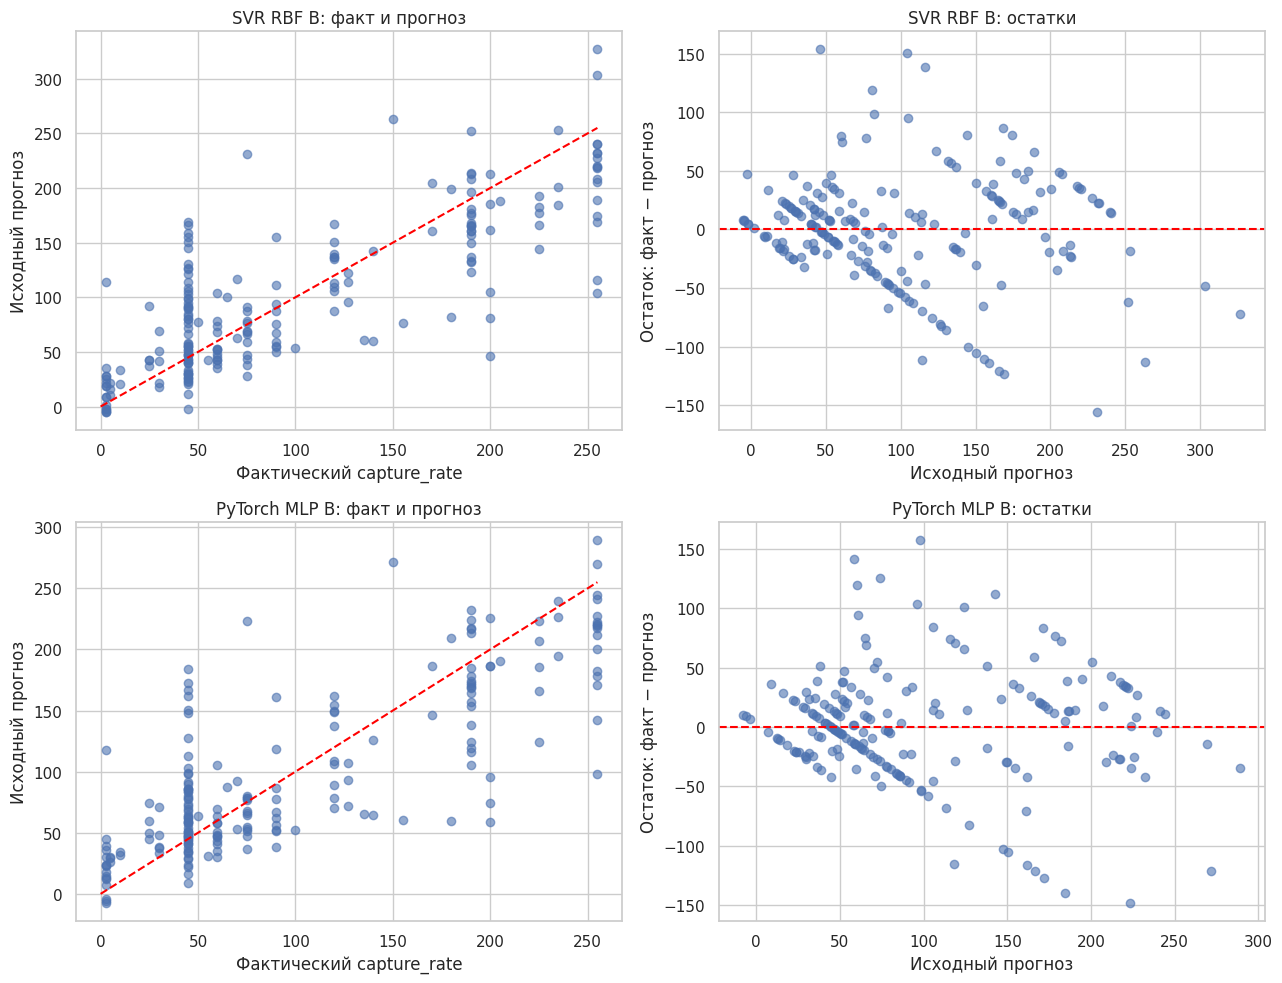

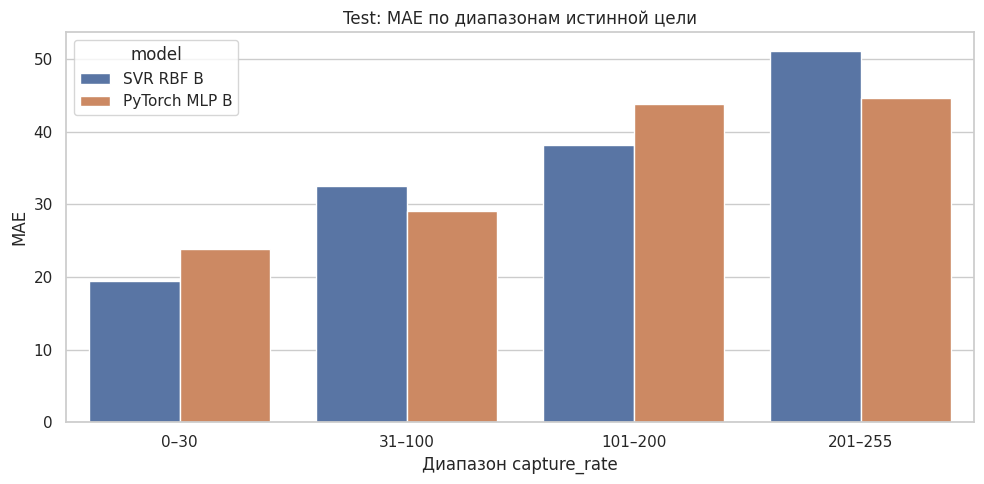

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for row, model_name in enumerate([
    "SVR RBF B",
    "PyTorch MLP B",
]):
    safe_name = model_name.lower().replace(" ", "_")

    actual = saved_predictions[TARGET].to_numpy()
    prediction = saved_predictions[
        f"{safe_name}_raw"
    ].to_numpy()

    residual = actual - prediction

    axes[row, 0].scatter(
        actual, prediction, alpha=0.6
    )
    axes[row, 0].plot(
        [0, 255], [0, 255], "--", color="red"
    )
    axes[row, 0].set_xlabel("Фактический capture_rate")
    axes[row, 0].set_ylabel("Исходный прогноз")
    axes[row, 0].set_title(f"{model_name}: факт и прогноз")

    axes[row, 1].scatter(
        prediction, residual, alpha=0.6
    )
    axes[row, 1].axhline(
        0, color="red", linestyle="--"
    )
    axes[row, 1].set_xlabel("Исходный прогноз")
    axes[row, 1].set_ylabel("Остаток: факт − прогноз")
    axes[row, 1].set_title(f"{model_name}: остатки")

save_plot("final_test_raw_predictions_and_residuals.png")

# MAE по диапазонам для исходных прогнозов.
range_plot = errors_by_range.loc[
    (errors_by_range["prediction_variant"] == "raw")
    & errors_by_range["model"].isin([
        "SVR RBF B", "PyTorch MLP B"
    ])
]

plt.figure(figsize=(10, 5))
sns.barplot(
    data=range_plot,
    x="target_range",
    y="MAE",
    hue="model",
    order=RANGE_LABELS,
    errorbar=None,
)
plt.title("Test: MAE по диапазонам истинной цели")
plt.xlabel("Диапазон capture_rate")
plt.ylabel("MAE")
save_plot("final_test_mae_by_range.png")

# Диапазоны используются только для анализа ошибок.
# Не переключаем модели по истинному диапазону:
# он неизвестен при предсказании нового объекта.

In [ ]:
validation_B = pd.DataFrame([
    {
        "model": "Dummy median B",
        "validation_MAE": 52.61875,
        "validation_RMSE": 75.84074597470676,
        "validation_R2": -0.15337392077220913,
    },
    {
        "model": "Dummy mean B",
        "validation_MAE": 60.32909743202417,
        "validation_RMSE": 71.09722492271418,
        "validation_R2": -0.01360847768672091,
    },
    {
        "model": "SVR RBF B",
        "validation_MAE": 34.11139765921301,
        "validation_RMSE": 47.74495951026737,
        "validation_R2": 0.5428907667412688,
    },
    {
        "model": "PyTorch MLP B",
        "validation_MAE": 32.570980072021484,
        "validation_RMSE": 47.804204243553464,
        "validation_R2": 0.5417555570602417,
    },
])

test_raw = saved_metrics.loc[
    saved_metrics["prediction_variant"] == "raw",
    ["model", "MAE", "RMSE", "R2"],
].rename(columns={
    "MAE": "test_MAE",
    "RMSE": "test_RMSE",
    "R2": "test_R2",
})

comparison = validation_B.merge(test_raw, on="model")

comparison["MAE_test_minus_validation"] = (
    comparison["test_MAE"] - comparison["validation_MAE"]
)

display(comparison.round(3))

comparison.to_csv(
    OUTPUT_DIR / "validation_vs_test_raw.csv",
    index=False,
)

print("Ранее выбранный кандидат:", SELECTED_MODEL)
print(
    "Test используется для итогового сравнения, "
    "а не для нового подбора параметров."
)

,model,validation_MAE,validation_RMSE,validation_R2,test_MAE,test_RMSE,test_R2,MAE_test_minus_validation
0,Dummy median B,52.619,75.841,-0.153,63.192,88.536,-0.259,10.573
1,Dummy mean B,60.329,71.097,-0.014,67.440,79.015,-0.003,7.111
2,SVR RBF B,34.111,47.745,0.543,34.351,47.072,0.644,0.240
3,PyTorch MLP B,32.571,47.804,0.542,33.790,46.772,0.649,1.219


Ранее выбранный кандидат: PyTorch MLP B
Test используется для итогового сравнения, а не для нового подбора параметров.
